## PART 2: SEQ2SEQ NEURAL MACHINE TRANSLATION
## BiLSTM Encoder + LSTM Decoder + Additive Attention

# 1. SETUP AND IMPORTS

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional
from collections import namedtuple
import time
from tqdm.auto import tqdm

import os
import shutil
from transformers import PreTrainedTokenizerFast
from datasets import load_from_disk

from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
import random

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
SRC_BASE = "/kaggle/input/resources/resources"

SRC_TOKENIZER_FR = f"{SRC_BASE}/tokenizer_fr"
SRC_TOKENIZER_EN = f"{SRC_BASE}/tokenizer_en"
SRC_DATASET      = f"{SRC_BASE}/parallel_en_fr_corpus"

DST_TOKENIZER_FR = "/kaggle/working/tokenizer_fr"
DST_TOKENIZER_EN = "/kaggle/working/tokenizer_en"
DST_DATASET      = "/kaggle/working/parallel_en_fr_corpus"

def copy_if_needed(src, dst):
    if not os.path.exists(src):
        raise FileNotFoundError(f"Source path not found: {src}")
    if os.path.exists(dst):
        print(f"Already exists: {dst}")
    else:
        shutil.copytree(src, dst)
        print(f"Copied {src} → {dst}")

copy_if_needed(SRC_TOKENIZER_FR, DST_TOKENIZER_FR)
copy_if_needed(SRC_TOKENIZER_EN, DST_TOKENIZER_EN)

copy_if_needed(SRC_DATASET, DST_DATASET)

Already exists: /kaggle/working/tokenizer_fr
Already exists: /kaggle/working/tokenizer_en
Already exists: /kaggle/working/parallel_en_fr_corpus


# 2. LOAD TOKENIZERS AND DATASET

In [13]:
print("Loading tokenizers")
src_tokenizer = PreTrainedTokenizerFast.from_pretrained("/kaggle/working/tokenizer_fr")
tgt_tokenizer = PreTrainedTokenizerFast.from_pretrained("/kaggle/working/tokenizer_en")

src_vocab_size = src_tokenizer.vocab_size
tgt_vocab_size = tgt_tokenizer.vocab_size

PAD_IDX = src_tokenizer.pad_token_id
SOS_IDX = src_tokenizer.bos_token_id if src_tokenizer.bos_token_id else 1
EOS_IDX = src_tokenizer.eos_token_id if src_tokenizer.eos_token_id else 2

print(f"Source vocab size: {src_vocab_size}")
print(f"Target vocab size: {tgt_vocab_size}")
print(f"PAD={PAD_IDX}, SOS={SOS_IDX}, EOS={EOS_IDX}")

print("\nLoading dataset")
dataset = load_from_disk("/kaggle/working/parallel_en_fr_corpus")

def encode_batch(batch):
    src = src_tokenizer(batch["text_fr"], truncation=True, max_length=64, padding=False)
    tgt = tgt_tokenizer(batch["text_en"], truncation=True, max_length=64, padding=False)
    return {"src_ids": src["input_ids"], "tgt_ids": tgt["input_ids"]}

dataset = dataset.map(encode_batch, batched=True, remove_columns=dataset["train"].column_names)
print(f"Dataset loaded: train={len(dataset['train'])}, val={len(dataset['validation'])}, test={len(dataset['test'])}")

Loading tokenizers
Source vocab size: 3200
Target vocab size: 3200
PAD=3, SOS=1, EOS=2

Loading dataset


Map:   0%|          | 0/485 [00:00<?, ? examples/s]

Dataset loaded: train=8701, val=485, test=486


# 3. DATASET CLASS AND DATALOADER

In [14]:
class TranslationDataset(Dataset):
    def __init__(self, src_data: List[List[int]], tgt_data: List[List[int]]):
        self.src_data = src_data
        self.tgt_data = tgt_data
        
    def __len__(self):
        return len(self.src_data)
    
    def __getitem__(self, idx):
        return {
            'src': torch.tensor(self.src_data[idx], dtype=torch.long),
            'tgt': torch.tensor(self.tgt_data[idx], dtype=torch.long)
        }

def collate_fn(batch):
    src_batch = [item['src'] for item in batch]
    tgt_batch = [item['tgt'] for item in batch]
    
    src_lengths = torch.tensor([len(s) for s in src_batch], dtype=torch.long)
    
    src_padded = pad_sequence(src_batch, batch_first=True, padding_value=PAD_IDX)
    tgt_padded = pad_sequence(tgt_batch, batch_first=True, padding_value=PAD_IDX)
    return {'src': src_padded, 'tgt': tgt_padded, 'src_lengths': src_lengths}

train_dataset = TranslationDataset(dataset["train"]["src_ids"], dataset["train"]["tgt_ids"])
val_dataset = TranslationDataset(dataset["validation"]["src_ids"], dataset["validation"]["tgt_ids"])
test_dataset = TranslationDataset(dataset["test"]["src_ids"], dataset["test"]["tgt_ids"])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

print("DataLoaders created")

DataLoaders created


# 4. MODEL COMPONENTS

In [15]:
class BiLSTMEncoder(nn.Module):
    def __init__(self, vocab_size: int, embed_size: int = 256, hidden_size: int = 512, dropout: float = 0.3):
        super().__init__()
        
        self.hidden_size = hidden_size
        
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx = PAD_IDX)
        
        self.lstm = nn.LSTM(embed_size, hidden_size, num_layers = 1, batch_first = True, bidirectional = True, dropout = 0.0)
        
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, src: torch.Tensor, src_lengths: torch.Tensor):
        embedded = self.dropout(self.embedding(src))
        
        packed = pack_padded_sequence(embedded, src_lengths.cpu(), batch_first = True, enforce_sorted = False)
        packed_outputs, (hidden, cell) = self.lstm(packed)
        
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first = True)
        
        return outputs, (hidden, cell)


class AdditiveAttention(nn.Module):
    def __init__(self, decoder_hidden_size: int = 512, encoder_hidden_size: int = 1024):
        super().__init__()
        
        self.W_a = nn.Linear(decoder_hidden_size, decoder_hidden_size, bias=False)
        self.U_a = nn.Linear(encoder_hidden_size, decoder_hidden_size, bias=False)
        
        self.v = nn.Linear(decoder_hidden_size, 1, bias=False)
        
    def forward(self, decoder_hidden: torch.Tensor, encoder_outputs: torch.Tensor, src_mask: Optional[torch.Tensor] = None):
        decoder_proj = self.W_a(decoder_hidden).unsqueeze(1)
        
        encoder_proj = self.U_a(encoder_outputs)
        
        alignment_scores = self.v(torch.tanh(decoder_proj + encoder_proj)).squeeze(2)
        
        if src_mask is not None:
            alignment_scores = alignment_scores.masked_fill(src_mask == 0, -1e9)
            
        attention_weights = F.softmax(alignment_scores, dim=1)
        
        context = torch.bmm(attention_weights.unsqueeze(1), encoder_outputs).squeeze(1)
        
        return context, attention_weights

        
class LSTMDecoder(nn.Module):
    def __init__(self, vocab_size: int, embed_size: int = 256, hidden_size: int = 512, encoder_hidden_size: int = 1024, dropout: float = 0.3):
        super().__init__()
        
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size
        self.embed_size = embed_size
        
        self.encoder_hidden_size = encoder_hidden_size
        
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=PAD_IDX)
        
        self.init_hidden_proj = nn.Linear(2 * hidden_size, hidden_size)
        self.init_cell_proj = nn.Linear(2 * hidden_size, hidden_size)
        
        self.attention = AdditiveAttention(hidden_size, encoder_hidden_size)
        
        self.lstm = nn.LSTM(embed_size + encoder_hidden_size, hidden_size, num_layers=1, batch_first=True, dropout=0.0)
        
        self.output_proj = nn.Linear(hidden_size + encoder_hidden_size + embed_size, vocab_size)
        
        self.dropout = nn.Dropout(dropout)
        
    def init_decoder_state(self, encoder_hidden, encoder_cell):
        hidden_concat = torch.cat([encoder_hidden[0], encoder_hidden[1]], dim=1)
        cell_concat = torch.cat([encoder_cell[0], encoder_cell[1]], dim=1)
        init_hidden = torch.tanh(self.init_hidden_proj(hidden_concat)).unsqueeze(0)
        init_cell = torch.tanh(self.init_cell_proj(cell_concat)).unsqueeze(0)
        
        return init_hidden, init_cell
    
    def forward_step(self, input_token, decoder_hidden, encoder_outputs, src_mask=None):
        embedded = self.dropout(self.embedding(input_token))
        
        prev_hidden = decoder_hidden[0].squeeze(0)
        
        context, attention_weights = self.attention(prev_hidden, encoder_outputs, src_mask)
        
        lstm_input = torch.cat([embedded, context], dim=1).unsqueeze(1)
        
        lstm_output, new_hidden = self.lstm(lstm_input, decoder_hidden)
        lstm_output = lstm_output.squeeze(1)
        
        output_input = torch.cat([lstm_output, context, embedded], dim=1)
        logits = self.output_proj(output_input)
        
        return logits, new_hidden, attention_weights
    
    def forward(self, encoder_outputs, encoder_hidden, tgt, src_mask=None, teacher_forcing_ratio=1.0):
        batch_size, tgt_len = tgt.size()
        
        decoder_hidden = self.init_decoder_state(encoder_hidden[0], encoder_hidden[1])
        
        outputs = torch.zeros(batch_size, tgt_len, self.vocab_size, device=tgt.device)
        
        attention_weights_list = []
        
        input_token = tgt[:, 0]
        
        for t in range(1, tgt_len):
            logits, decoder_hidden, attn = self.forward_step(input_token, decoder_hidden, encoder_outputs, src_mask)
            
            outputs[:, t] = logits
            
            attention_weights_list.append(attn)
            
            use_teacher_forcing = torch.rand(1).item() < teacher_forcing_ratio
            
            input_token = tgt[:, t] if use_teacher_forcing else logits.argmax(dim=1)
        
        return outputs, attention_weights_list


class Seq2SeqRNN(nn.Module):
    def __init__(self, src_vocab_size: int, tgt_vocab_size: int, embed_size: int = 256, hidden_size: int = 512, dropout: float = 0.3):
        super().__init__()
        
        self.encoder = BiLSTMEncoder(src_vocab_size, embed_size, hidden_size, dropout)
        self.decoder = LSTMDecoder(tgt_vocab_size, embed_size, hidden_size, 2*hidden_size, dropout)
        
    def forward(self, src, src_lengths, tgt, teacher_forcing_ratio=1.0):
        max_src_len = src.size(1)
        
        src_mask = (torch.arange(max_src_len, device=src.device).unsqueeze(0) < src_lengths.unsqueeze(1))
        
        encoder_outputs, encoder_hidden = self.encoder(src, src_lengths)
        
        outputs, attention_weights = self.decoder(encoder_outputs, encoder_hidden, tgt, src_mask, teacher_forcing_ratio)
        
        return outputs, attention_weights

# 5. TRAINING FUNCTIONS

In [16]:
def train_epoch(model, dataloader, optimizer, criterion, device, grad_clip=1.0, teacher_forcing_ratio=1.0):
    model.train()
    total_loss = 0
    
    for batch in tqdm(dataloader, desc="Training", leave=False):
        src, tgt, src_lengths = batch['src'].to(device), batch['tgt'].to(device), batch['src_lengths'].to(device)
        optimizer.zero_grad()
        
        outputs, _ = model(src, src_lengths, tgt, teacher_forcing_ratio)
        outputs = outputs[:, 1:].contiguous()
        
        tgt = tgt[:, 1:].contiguous()
        
        loss = criterion(outputs.view(-1, outputs.size(-1)), tgt.view(-1))
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        total_loss += loss.item()
        
    return total_loss / len(dataloader)

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Evaluating", leave=False):
            src, tgt, src_lengths = batch['src'].to(device), batch['tgt'].to(device), batch['src_lengths'].to(device)
            
            outputs, _ = model(src, src_lengths, tgt, teacher_forcing_ratio=0.0)
            outputs = outputs[:, 1:].contiguous()
            
            tgt = tgt[:, 1:].contiguous()
            loss = criterion(outputs.view(-1, outputs.size(-1)), tgt.view(-1))
            total_loss += loss.item()
            
    return total_loss / len(dataloader)

# 6. BEAM SEARCH

In [17]:
BeamHypothesis = namedtuple('BeamHypothesis', ['tokens', 'log_prob', 'hidden', 'attention'])

class BeamSearchDecoder:
    def __init__(self, model, beam_size=5, max_length=32, sos_idx=SOS_IDX, eos_idx=EOS_IDX):
        self.model = model
        
        self.beam_size = beam_size
        self.max_length = max_length
        
        self.sos_idx = sos_idx
        self.eos_idx = eos_idx
        
    def decode(self, src, src_lengths):
        batch_size, device = src.size(0), src.device
        max_src_len = src.size(1)
        
        src_mask = (torch.arange(max_src_len, device=device).unsqueeze(0) < src_lengths.unsqueeze(1))
        
        encoder_outputs, encoder_hidden = self.model.encoder(src, src_lengths)
        
        results = []
        
        for b in range(batch_size):
            enc_out = encoder_outputs[b:b+1]
            
            mask = src_mask[b:b+1]
            
            hidden = self.model.decoder.init_decoder_state(encoder_hidden[0][:, b:b+1], encoder_hidden[1][:, b:b+1])
            
            beams = [BeamHypothesis(tokens=[self.sos_idx], log_prob=0.0, hidden=hidden, attention=[])]
            
            completed = []
            
            for step in range(self.max_length):
                if len(beams) == 0:
                    break
                
                all_candidates = []
                for beam in beams:
                    if beam.tokens[-1] == self.eos_idx:
                        completed.append(beam)
                        continue
                    
                    token_tensor = torch.tensor([beam.tokens[-1]], device=device)
                    
                    logits, new_hidden, attn = self.model.decoder.forward_step(token_tensor, beam.hidden, enc_out, mask)
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    top_log_probs, top_indices = log_probs.topk(self.beam_size, dim=1)
                    
                    for k in range(self.beam_size):
                        token = top_indices[0, k].item()
                        
                        log_prob = beam.log_prob + top_log_probs[0, k].item()
                        
                        new_beam = BeamHypothesis(tokens=beam.tokens + [token], log_prob=log_prob, hidden=new_hidden, attention=beam.attention + [attn])
                        
                        all_candidates.append(new_beam)
                    
                all_candidates.sort(key=lambda x: x.log_prob / len(x.tokens), reverse=True)
                
                beams = all_candidates[:self.beam_size]
            
            all_hyps = completed + beams
            all_hyps.sort(key=lambda x: x.log_prob / len(x.tokens), reverse=True)
            
            best_tokens = all_hyps[0].tokens[1:]
            
            if best_tokens and best_tokens[-1] == self.eos_idx:
                best_tokens = best_tokens[:-1]
            
            results.append(best_tokens)
            
        return results

# 7. BLEU EVALUATION

In [18]:
def compute_bleu_scores(model, dataloader, device, beam_size = 5):
    model.eval()
    
    beam_decoder = BeamSearchDecoder(model, beam_size = beam_size, sos_idx = SOS_IDX, eos_idx = EOS_IDX)
    
    all_references = []
    all_hypotheses = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Computing BLEU", leave=False):
            src, tgt = batch['src'].to(device), batch['tgt'].cpu().numpy()
            src_lengths = batch['src_lengths'].to(device)
            predictions = beam_decoder.decode(src, src_lengths)
            
            for pred_indices, ref_indices in zip(predictions, tgt):
                pred_tokens = [idx for idx in pred_indices if idx not in [PAD_IDX, SOS_IDX, EOS_IDX]]
                ref_tokens = [idx for idx in ref_indices if idx not in [PAD_IDX, SOS_IDX, EOS_IDX]]
                all_hypotheses.append(pred_tokens)
                all_references.append([ref_tokens])
    
    bleu_scores = {}
    smoothing = SmoothingFunction().method1
    
    for n in range(1, 5):
        weights = tuple([1.0/n] * n + [0.0] * (4-n))
        
        bleu = corpus_bleu(all_references, all_hypotheses, weights=weights, smoothing_function=smoothing)
        bleu_scores[f'BLEU-{n}'] = bleu * 100
        
    return bleu_scores

# 8. CHECKPOINTING

In [19]:
def save_checkpoint(model, optimizer, epoch, loss, config, path='checkpoint.pt'):
    torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),'optimizer_state_dict': optimizer.state_dict(), 'loss': loss, 'config': config}, path)
    
    print(f"Checkpoint saved to {path}")

def load_checkpoint(path, model, optimizer=None):
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    
    if optimizer:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        
    return checkpoint['epoch'], checkpoint['loss'], checkpoint.get('config', {})

# 9. TRAINING

In [20]:
config = {
    'src_vocab_size': src_vocab_size, 'tgt_vocab_size': tgt_vocab_size,
    'embed_size': 256, 'hidden_size': 512, 'dropout': 0.3,
    'batch_size': 32, 'learning_rate': 1e-3, 'num_epochs': 10,
    'grad_clip': 1.0, 'teacher_forcing_ratio': 1.0, 'beam_size': 5
}

model = Seq2SeqRNN(config['src_vocab_size'], config['tgt_vocab_size'], config['embed_size'], config['hidden_size'], config['dropout']).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])

print(f"Model has {sum(p.numel() for p in model.parameters()):,} parameters")

# Training
best_val_loss = float('inf')
for epoch in range(config['num_epochs']):
    print(f"\nEpoch {epoch+1}/{config['num_epochs']}")
    train_loss = train_epoch(model, train_loader, optimizer, criterion, device, config['grad_clip'], config['teacher_forcing_ratio'])
    val_loss = evaluate(model, val_loader, criterion, device)
    
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        save_checkpoint(model, optimizer, epoch+1, val_loss, config, 'best_model.pt')

# Evaluation
test_loss = evaluate(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.4f}")

bleu_scores = compute_bleu_scores(model, test_loader, device, config['beam_size'])

for metric, score in bleu_scores.items():
    print(f"{metric}: {score:.2f}")

print("\nTraining and evaluation complete")

Model has 16,040,576 parameters

Epoch 1/10


Training:   0%|          | 0/272 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 2.5776 | Val Loss: 3.0004
Checkpoint saved to best_model.pt

Epoch 2/10


Training:   0%|          | 0/272 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/16 [00:00<?, ?it/s]

... (25 outputs left out)

Evaluating:   0%|          | 0/16 [00:00<?, ?it/s]

Test Loss: 2.8785


Computing BLEU:   0%|          | 0/16 [00:00<?, ?it/s]

BLEU-1: 77.80
BLEU-2: 69.28
BLEU-3: 62.98
BLEU-4: 58.21

Training and evaluation complete



Example 1
--------------------------------------------------------------------------------
🇫🇷 Source (FR): ▁vous ▁etes ▁tous ▁h y p oc ri tes ▁.
Reference (EN): ▁you ▁re ▁all ▁hy p oc rit ical ▁.
Prediction (EN): ▁you ▁re ▁all ▁disappointed ▁.


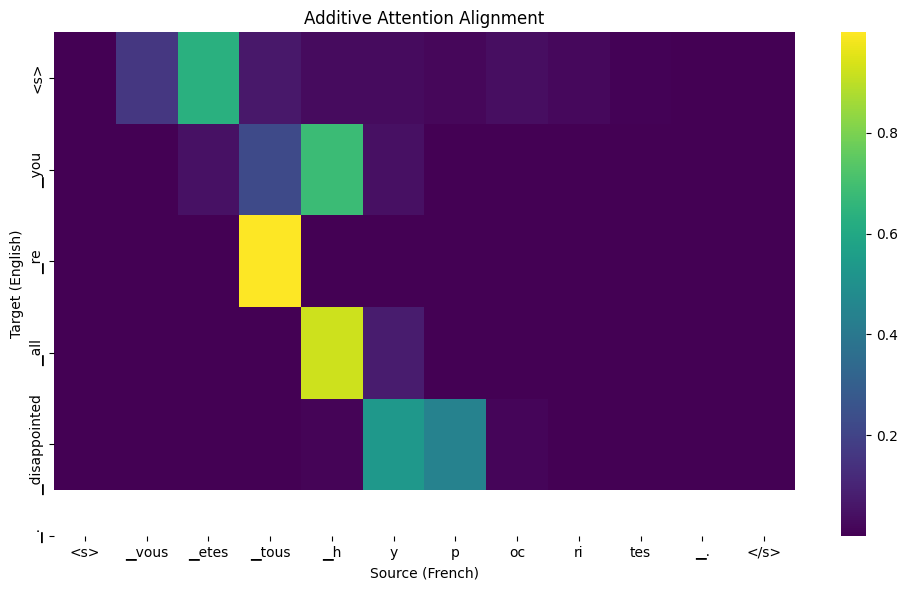


Example 2
--------------------------------------------------------------------------------
🇫🇷 Source (FR): ▁tu ▁es ▁un ▁merveille ux ▁ami ▁.
Reference (EN): ▁you ▁re ▁a ▁wonderful ▁friend ▁.
Prediction (EN): ▁you ▁re ▁a ▁wonderful ▁guy ▁.


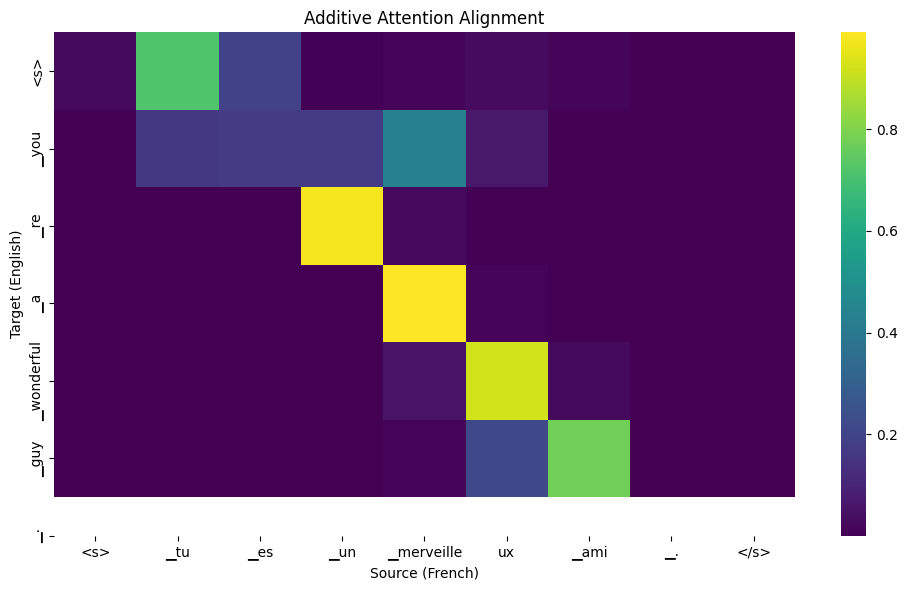


Example 3
--------------------------------------------------------------------------------
🇫🇷 Source (FR): ▁il ▁est ▁toujours ▁debout ▁.
Reference (EN): ▁he ▁is ▁still ▁stand ing ▁.
Prediction (EN): ▁he ▁is ▁always ▁full ▁.


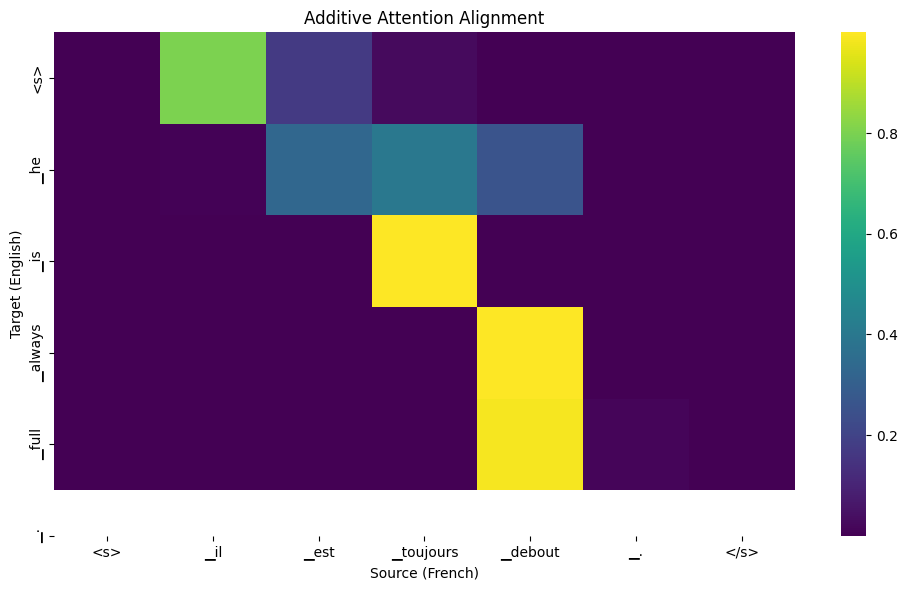


Example 4
--------------------------------------------------------------------------------
🇫🇷 Source (FR): ▁je ▁crains ▁qu ▁il ▁commette ▁une ▁erreur ▁.
Reference (EN): ▁i ▁am ▁afraid ▁he ▁will ▁make ▁a ▁mistake ▁.
Prediction (EN): ▁i ▁am ▁afraid ▁he ▁will ▁make ▁a ▁mistake ▁.


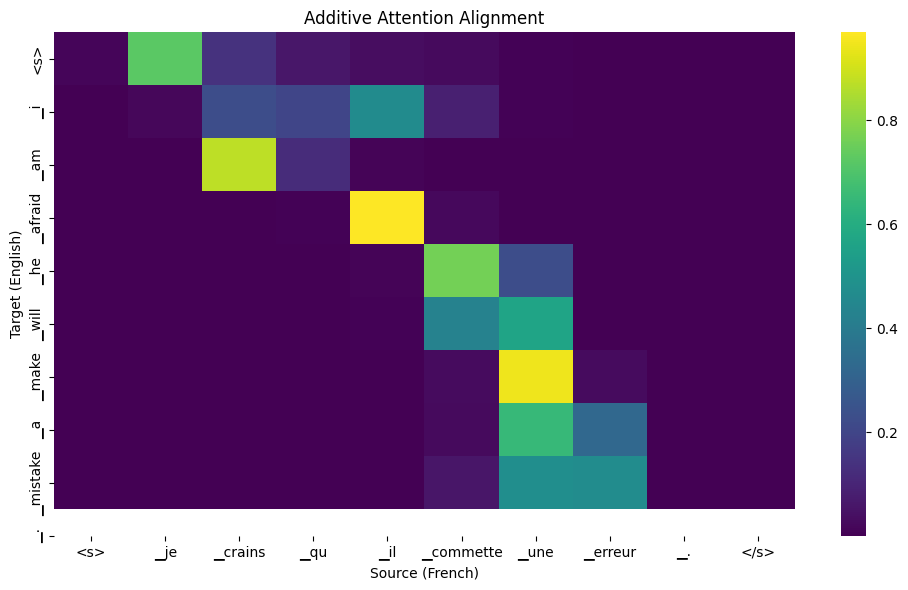


Example 5
--------------------------------------------------------------------------------
🇫🇷 Source (FR): ▁vous ▁etes ▁vraiment ▁incroy ables ▁.
Reference (EN): ▁you ▁re ▁really ▁incredible ▁.
Prediction (EN): ▁you ▁re ▁really ▁annoying ▁.


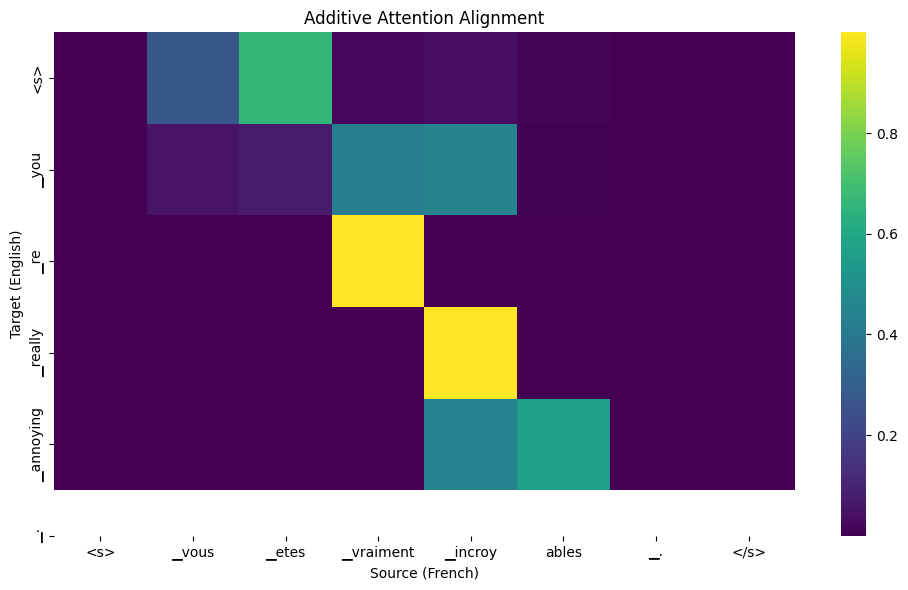

In [21]:
model.eval()

num_examples = 5
indices = random.sample(range(len(test_dataset)), num_examples)

beam_decoder = BeamSearchDecoder(
    model,
    beam_size=config['beam_size'],
    max_length=32,
    sos_idx=SOS_IDX,
    eos_idx=EOS_IDX
)

def plot_attention(attn_weights, src_tokens, tgt_tokens):
    """
    attn_weights: [tgt_len, src_len]
    """
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        attn_weights,
        xticklabels=src_tokens,
        yticklabels=tgt_tokens,
        cmap="viridis"
    )
    plt.xlabel("Source (French)")
    plt.ylabel("Target (English)")
    plt.title("Additive Attention Alignment")
    plt.tight_layout()
    plt.show()

for i, idx in enumerate(indices):
    sample = test_dataset[idx]
    
    src = sample['src'].unsqueeze(0).to(device)
    tgt = sample['tgt'].unsqueeze(0).to(device)
    src_lengths = torch.tensor([len(sample['src'])], device=device)

    # Decode
    with torch.no_grad():
        predictions = beam_decoder.decode(src, src_lengths)

    pred_ids = predictions[0]
    
    # Decode tokens
    src_text = src_tokenizer.decode(
        sample['src'].tolist(),
        skip_special_tokens=True
    )
    
    tgt_text = tgt_tokenizer.decode(
        sample['tgt'].tolist(),
        skip_special_tokens=True
    )
    
    pred_text = tgt_tokenizer.decode(
        pred_ids,
        skip_special_tokens=True
    )

    print(f"\nExample {i+1}")
    print("-"*80)
    print(f"🇫🇷 Source (FR): {src_text}")
    print(f"Reference (EN): {tgt_text}")
    print(f"Prediction (EN): {pred_text}")

    # Run greedy decoding once to collect attention weights
    with torch.no_grad():
        encoder_outputs, encoder_hidden = model.encoder(src, src_lengths)
        src_mask = (torch.arange(src.size(1), device=device)
                    .unsqueeze(0) < src_lengths.unsqueeze(1))
        
        decoder_hidden = model.decoder.init_decoder_state(
            encoder_hidden[0], encoder_hidden[1]
        )

        input_token = torch.tensor([SOS_IDX], device=device)
        attention_matrix = []

        max_steps = min(len(pred_ids), 20)

        for _ in range(max_steps):
            logits, decoder_hidden, attn = model.decoder.forward_step(
                input_token,
                decoder_hidden,
                encoder_outputs,
                src_mask
            )
            attention_matrix.append(attn.squeeze(0).cpu().numpy())
            input_token = logits.argmax(dim=1)

    attention_matrix = np.stack(attention_matrix, axis=0)

    # Token labels for visualization
    src_tokens = src_tokenizer.convert_ids_to_tokens(sample['src'].tolist())
    tgt_tokens = tgt_tokenizer.convert_ids_to_tokens([SOS_IDX] + pred_ids[:attention_matrix.shape[0]])

    plot_attention(attention_matrix, src_tokens, tgt_tokens)